In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import json, pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow import keras
from keras.utils import set_random_seed
from keras.models import Model
from keras.optimizers import Adam
from keras.layers import Conv1D, Dropout, BatchNormalization, Activation, add, Bidirectional, LSTM, GRU, Input, Dense

In [ ]:
PICKLE_PATH = "/content/drive/MyDrive/AUT/Project/Features/DATA_MFCC30.pkl"

In [ ]:
def load_data():
    with open(PICKLE_PATH_TRAIN, "rb") as input:
        DATA_TRAIN = pickle.load(input)

    with open(PICKLE_PATH_TEST, "rb") as input:
        DATA_TEST = pickle.load(input)

    with open(PICKLE_PATH_DEV, "rb") as input:
        DATA_DEV = pickle.load(input)

    X_train = np.array(DATA_TRAIN["mfccs"], dtype=np.float32)
    y1_train = np.array(DATA_TRAIN["labels"]["instrument"], dtype=np.int8)
    y2_train = np.array(DATA_TRAIN["labels"]["scale"], dtype=np.int8)
    X_train, y1_train, y2_train = sk_shuffle(X_train, y1_train, y2_train)

    X_test = np.array(DATA_TEST["mfccs"], dtype=np.float32)
    y1_test = np.array(DATA_TEST["labels"]["instrument"], dtype=np.int8)
    y2_test = np.array(DATA_TEST["labels"]["scale"], dtype=np.int8)
    X_test, y1_test, y2_test = sk_shuffle(X_test, y1_test, y2_test)

    X_val = np.array(DATA_DEV["mfccs"], dtype=np.float32)
    y1_val = np.array(DATA_DEV["labels"]["instrument"], dtype=np.int8)
    y2_val = np.array(DATA_DEV["labels"]["scale"], dtype=np.int8)
    X_val, y1_val, y2_val = sk_shuffle(X_val, y1_val, y2_val)

    return X_train, X_test, X_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val

In [ ]:
def Residual_Conv1D(model, num_filters=512):

    def conv1D(model, dropout):
        model = Conv1D(filters=num_filters, kernel_size=5, padding='same')(model)
        model = Dropout(dropout)(model)
        model = BatchNormalization()(model)
        model = Activation('relu')(model)
        return model

    model_in = model

    model = conv1D(model, dropout=0.1)
    model = conv1D(model, dropout=0.2)

    shortcut = Conv1D(filters=num_filters, kernel_size=3, padding='same')(model_in)
    shortcut = BatchNormalization()(shortcut)

    model_out = add([shortcut, model])
    model_out = Activation('relu')(model_out)

    return model_out

In [ ]:
def Encoder(model):

    def BiLSTM(model, num_units, return_seq=True):
        model = Bidirectional(LSTM(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model

    model = BiLSTM(model, num_units=256)
    model = BiLSTM(model, num_units=128)
    model = BiLSTM(model, num_units=64)

    return model

In [ ]:
def Decoder(model):

    def BiGRU(model, num_units, return_seq=True):
        model = Bidirectional(GRU(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model

    model = BiGRU(model, num_units=32)
    model = BiGRU(model, num_units=64)
    model = BiGRU(model, num_units=128)
    model = BiGRU(model, num_units=256, return_seq=False)

    return model

In [ ]:
def BiRNN(model):

    def BiGRU(model, num_units, return_seq=True):
        model = Bidirectional(GRU(units=num_units, return_sequences=return_seq))(model)
        model = BatchNormalization()(model)
        return model

    model = BiGRU(model, num_units=1024)
    model = BiGRU(model, num_units=1024)
    # model = BiGRU(model, num_units=256)
    model = BiGRU(model, num_units=512)
    model = BiGRU(model, num_units=512, return_seq=False)

    return model

In [ ]:
def FC_Dense(model, unit):
    model = Dense(units=unit, activation='relu', kernel_regularizer=keras.regularizers.l2(0.05))(model)
    model = Dropout(0.5)(model)

    return model

In [ ]:
def Output(models):
    y1_output = Dense(units=5, activation='softmax', name='instrument')(models[0])
    y2_output = Dense(units=7, activation='softmax', name='scale')(models[1])

    return (y1_output, y2_output)

In [ ]:
def build_model(input_shape) -> Model:

    input = Input(input_shape)
    model = Residual_Conv1D(input)

    model = BiRNN(model)

    model_1 = FC_Dense(model, unit=16)
    model_2 = FC_Dense(model, unit=24)
    output = Output((model_1, model_2))
    model = Model(inputs=input, outputs=output)

    return model

In [ ]:
X_train, X_test, X_val, y1_train, y1_test, y1_val, y2_train, y2_test, y2_val = load_data()
Y_train = (y1_train, y2_train)
Y_test = (y1_test, y2_test)
Y_val = (y1_val, y2_val)

del y1_train, y1_test, y1_val, y2_train, y2_test, y2_val

In [ ]:
set_random_seed(0)
model = build_model(input_shape=(X_train.shape[1], X_train.shape[2]))
# model.summary()

optimizer = Adam(learning_rate=0.001)
model.compile(
    optimizer=optimizer,
    loss={
        'instrument': 'sparse_categorical_crossentropy',
        'scale': 'sparse_categorical_crossentropy'
    },
    metrics={
        'instrument': ['accuracy'],
        'scale': ['accuracy']
    }
)

history = model.fit(X_train, Y_train,
                    validation_data=(X_val, Y_val),
                    batch_size=128,
                    epochs=50)

Epoch 1/50
60/60 [==============================] - 165s 3s/step - loss: 6.3042 - instrument_loss: 0.9004 - scale_loss: 2.3028 - instrument_accuracy: 0.6944 - scale_accuracy: 0.1797 - val_loss: 5.2313 - val_instrument_loss: 0.9413 - val_scale_loss: 1.9728 - val_instrument_accuracy: 0.6509 - val_scale_accuracy: 0.1775
Epoch 2/50
60/60 [==============================] - 147s 2s/step - loss: 4.1153 - instrument_loss: 0.4493 - scale_loss: 1.9061 - instrument_accuracy: 0.8319 - scale_accuracy: 0.2272 - val_loss: 3.5277 - val_instrument_loss: 0.4326 - val_scale_loss: 1.8210 - val_instrument_accuracy: 0.8787 - val_scale_accuracy: 0.2663
Epoch 3/50
60/60 [==============================] - 148s 2s/step - loss: 3.0266 - instrument_loss: 0.3215 - scale_loss: 1.7365 - instrument_accuracy: 0.8881 - scale_accuracy: 0.3088 - val_loss: 2.4296 - val_instrument_loss: 0.1214 - val_scale_loss: 1.5985 - val_instrument_accuracy: 0.9601 - val_scale_accuracy: 0.4038
Epoch 4/50
60/60 [=========================

In [ ]:
loss, instrument_loss, scale_loss, instrument_accuracy, scale_accuracy = model.evaluate(X_test, Y_test)
print(f"\nTest Results:\n")
print(f"Total Loss: {loss}")
print(f"Instrument Loss: {instrument_loss}")
print(f"Scale Loss: {scale_loss}")
print(f"Instrument Accuracy on Test Set: {instrument_accuracy}")
print(f"Scale Accuracy on Test Set: {scale_accuracy}")

22/22 [==============================] - 6s 237ms/step - loss: 0.4948 - instrument_loss: 0.0133 - scale_loss: 0.3902 - instrument_accuracy: 0.9956 - scale_accuracy: 0.9244

Test Results:

Total Loss: 0.4947868883609772
Instrument Loss: 0.01327831856906414
Scale Loss: 0.39016810059547424
Instrument Accuracy on Test Set: 0.995555579662323
Scale Accuracy on Test Set: 0.9244444370269775


In [ ]:
def plot_history(history):

    def plot_result(metrics, labels, y_label, title, location):
        plt.plot(history.history[metrics[0]], label=labels[0])
        plt.plot(history.history[metrics[1]], label=labels[1])
        plt.title(title)
        plt.xlabel("Epoch")
        plt.ylabel(y_label)
        plt.legend(loc=location)
        # plt.savefig("/content/drive/MyDrive/proj/pic/MFCC_B128_E130_M30/" + title + ".png")
        plt.show()
        print("\n\n")

    # create accuracy sublpot
    plot_result(metrics=("instrument_accuracy", "val_instrument_accuracy"),
                 labels=("Instrument Train Accuracy", "Instrument Test Accuracy"),
                 y_label="Accuracy", title="Instrument Accuracy Evaluation", location="lower right")

    plot_result(metrics=("instrument_loss", "val_instrument_loss"),
                 labels=("Instrument Train Error", "Instrument Test Error"),
                 y_label="Loss", title="Instrument Error Evaluation", location="upper right")

    plot_result(metrics=("scale_accuracy", "val_scale_accuracy"),
                 labels=("Scale Train Accuracy", "Scale Test Accuracy"),
                 y_label="Accuracy", title="Scale Accuracy Evaluation", location="lower right")

    plot_result(metrics=("scale_loss", "val_scale_loss"),
                 labels=("Scale Train Error", "Scale Test Error"),
                 y_label="Loss", title="Scale Error Evaluation", location="upper right")

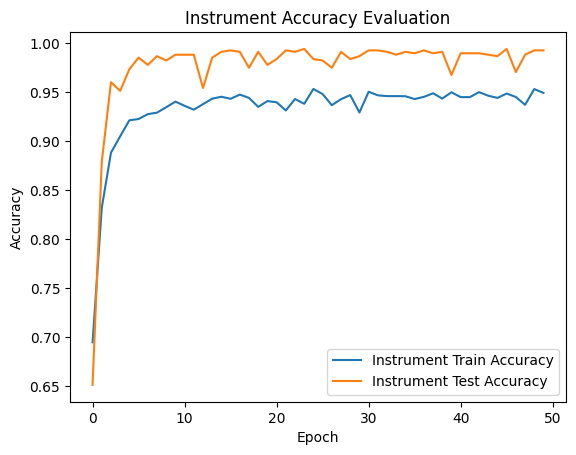

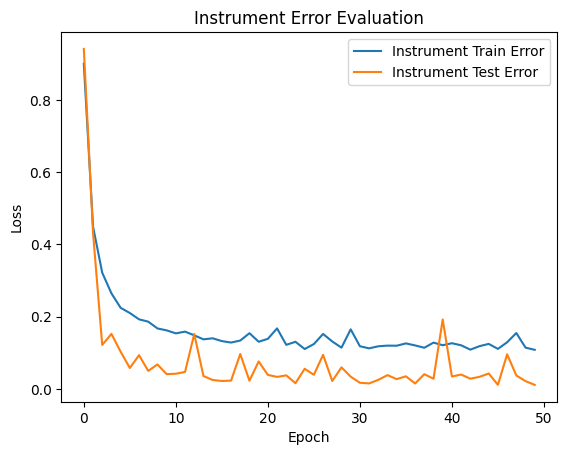

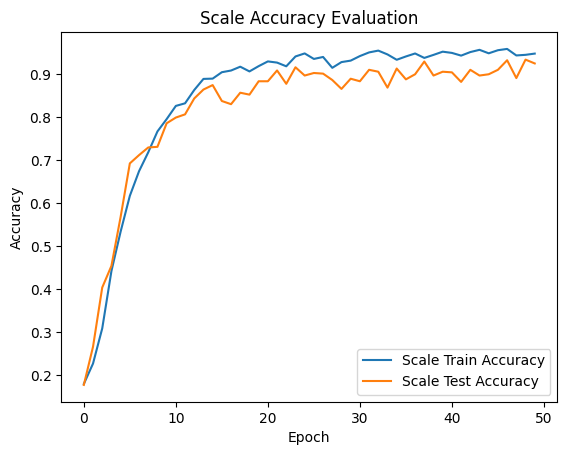

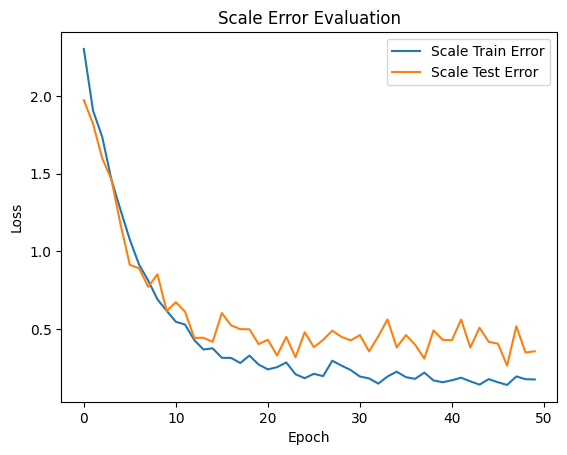

In [ ]:
plot_history(history)

In [ ]:
# model.save(filepath="/content/drive/MyDrive/proj/models/MFCC_B128_E130_M30")